# 13 · Label levels: one augmentation, several ground truths (double tree)

The double-tree generator separates **what shapes the labels** from **what paints the image**,
and writes **one ground truth per label level** for every synthetic image.

| input | here | used for |
|---|---|---|
| **L** label maps | `nxbsimplified/labels/case-*.nii.gz` (231 labels, 0.2 mm) | HR templates |
| **MT** morphological tree | `nextbrain_tree_allen_gyral_simplified.json` | label space of L, morphology pairs |
| **SM** merging scripts | `nxbsimplified_to_nxb16.py`, `nxbsimplified_to_nxbsupersynth.py` (+ identity) | one GT per level |
| **SMP** principal script | `nxb16` | the level the image is made from |
| **IT** intensity tree | `nextbrain_tree_nxb16.json` (= tree of the principal level) | Gaussians of the image |
| **C** config | `configs/nxbsimplified_levels.json` | every setting |

```
 L ──► HR templates (fine labels, MT label space)                         [offline / as is]
                    │
   per image (online, GPU)
                    ▼
        crop ► morphology (MT pairs) ► spatial           → augmented FINE HR labels (0.2 mm)
                    │
                    ├─► merge nxb_all (identity) ─► partial volume ─► GT nxb_all       (0.4 mm)
                    ├─► merge nxbsupersynth ──────► partial volume ─► GT nxbsupersynth (0.4 mm)
                    └─► merge nxb16 (principal) ──► partial volume ─► GT nxb16         (0.4 mm)
                                                          │ top-k fractions
                                                          ▼
                                     synthesis with the IT Gaussians (one per nxb16 class)
                                                          ▼
                              bias ► motion ► resolution + noise ► normalisation ► IMAGE
```

**The merge is online**, after the augmentation, on every image. The only thing prepared in
advance (when the `Generator` is created, in memory) is the small table that says which merged
label each fine label becomes.

Contents:

1. the inputs and the config section `merging`
2. what happens when the generator starts: mapping → lookup table → label space per level
3. one image and its three ground truths
4. inside `render`: the merge and the partial volume of every level
5. why merge **before** the partial volume
6. the image comes from the principal level and IT
7. changing the principal level
8. saving datasets, checks and errors, cost

In [1]:
from _setup import *
import json, time
from nxgen import Generator, Recorder, load_config
from nxgen.core.tree import load_tree
from nxgen.core.merging import load_script
print('device     :', DEVICE)
print('config C   :', DT_CONFIG)
print('labels L   :', DT_LABELS, sorted(os.listdir(DT_LABELS)))
print('template   :', DT_TEMPLATE, '(L is already at 0.2 mm: used directly as HR template)')

device     : cuda:3
config C   : /home/agustin/phd/synthseg_nextbrain/project/dev2/generator/generator_double_tree/configs/nxbsimplified_levels.json
labels L   : /home/agustin/phd/synthseg_nextbrain/project/dev2/simplified_trees_and_labels/data/outputs/nxbsimplified/labels ['case-1.nii.gz', 'case-2.nii.gz', 'case-3.nii.gz', 'case-4.nii.gz', 'case-5.nii.gz']
template   : /home/agustin/phd/synthseg_nextbrain/project/dev2/simplified_trees_and_labels/data/outputs/nxbsimplified/labels/case-1.nii.gz (L is already at 0.2 mm: used directly as HR template)


## 1. The inputs and the `merging` section

The config is the usual one (same sections as `generator_tree`) plus one section, `merging`:

* `levels`: `{name: null | {"script", "tree", "options"}}`.
  * `null` = the fine labels themselves (identity, tree = MT);
  * otherwise a merging script and the tree of the merged labels (`options` are passed to the
    script).
* `principal`: the level the image is synthesised from. **Its tree is the intensity tree IT.**

`labels.tree` is still MT: it defines the fine label space of the templates and the names used by
the morphology pairs. Relative paths are relative to the config file.

In [2]:
cfg = load_config(DT_CONFIG)
print('labels.tree (MT):', os.path.relpath(cfg['labels']['tree'], DEV2))
print('principal       :', cfg['merging']['principal'])
for name, spec in cfg['merging']['levels'].items():
    if spec is None:
        print(f'level {name:14s} identity (fine labels, MT)')
    else:
        print(f'level {name:14s} script {os.path.basename(spec["script"])}\n'
              f'{"":20s} tree   {os.path.relpath(spec["tree"], DEV2)}  options {spec.get("options", {})}')
print('\nmorphology pairs use MT names, e.g.', cfg['morphology']['pairs'][0])

labels.tree (MT): simplified_trees_and_labels/data/outputs/nxbsimplified/nextbrain_tree_allen_gyral_simplified.json
principal       : nxb16
level nxb_all        identity (fine labels, MT)
level nxb16          script nxbsimplified_to_nxb16.py
                     tree   simplified_trees_and_labels/data/outputs/nxb16/nextbrain_tree_nxb16.json  options {}
level nxbsupersynth  script nxbsimplified_to_nxbsupersynth.py
                     tree   simplified_trees_and_labels/data/outputs/nxbsupersynth/nextbrain_tree_nxbsupersynth.json  options {'side': 'R', 'claustrum': False}

morphology pairs use MT names, e.g. ['background', 'surface_structures_of_forebrain_l1']


In [3]:
MT = load_tree(cfg['labels']['tree'])
for name, spec in cfg['merging']['levels'].items():
    t = MT if spec is None else load_tree(spec['tree'])
    print(f'{name:14s} tree {t.version!r:45s} {len(t.nodes):4d} nodes {len(t.label_to_node):4d} labels '
          f'{len(t.colors):3d} colors')

nxb_all        tree 'nextbrain-allen-gyral-0.3-nxbsimplified'      356 nodes  231 labels  10 colors
nxb16          tree 'nextbrain-nxb16-0.2'                           18 nodes   17 labels   7 colors
nxbsupersynth  tree 'nextbrain-nxbsupersynth-0.2'                   20 nodes   19 labels  18 colors


/home/agustin/phd/synthseg_nextbrain/project/dev2/libraries/trees/tree.py:387: UserWarning: gray_matter_of_forebrain_l1: r_max on level-1 nodes is ignored (always visible). Group structures that merge at coarse resolution under a common parent.
  warnings.warn(w)
/home/agustin/phd/synthseg_nextbrain/project/dev2/libraries/trees/tree.py:387: UserWarning: white_matter_of_forebrain_l1: r_max on level-1 nodes is ignored (always visible). Group structures that merge at coarse resolution under a common parent.
  warnings.warn(w)
/home/agustin/phd/synthseg_nextbrain/project/dev2/libraries/trees/tree.py:387: UserWarning: surface_structures_of_forebrain_l1: r_max on level-1 nodes is ignored (always visible). Group structures that merge at coarse resolution under a common parent.
  warnings.warn(w)
/home/agustin/phd/synthseg_nextbrain/project/dev2/libraries/trees/tree.py:387: UserWarning: gray_matter_of_midbrain_l1: r_max on level-1 nodes is ignored (always visible). Group structures that merge 

MT is deep (356 nodes, gyral parcellation); nxb16 and nxbsupersynth are flat trees (one level-1
node per class). The intensity model of the image is therefore the nxb16 model: 7 principal colours
(WM, GM, ...) mixed with the GMM weights of each class.

## 2. When the generator starts: mapping → lookup table → label space

A merging script must define one function:

```python
def label_mapping(**options):   # -> {fine raw label: merged raw label}
```

It is the same rule the script applies to label maps on disk (its *step 2*); the scripts
themselves are unchanged otherwise and still work from the command line. For `nxb16` it is read
from `GMM_label_grouping_corrected.yaml` (new id = position of the class); for `nxbsupersynth`
from `nextbrain_utils.to_supersynth` (with `side='R'`, `claustrum=False`).

In [4]:
spec16 = cfg['merging']['levels']['nxb16']
map16 = load_script(spec16['script']).label_mapping()
specss = cfg['merging']['levels']['nxbsupersynth']
mapss = load_script(specss['script']).label_mapping(**specss['options'])
print('nxb16         mapping:', len(map16), 'entries, e.g.', {k: map16[k] for k in [0, 3, 7, 99, 103]})
print('nxbsupersynth mapping:', len(mapss), 'entries, e.g.', {k: mapss[k] for k in [0, 3, 7, 99, 103]})

nxb16         mapping: 266 entries, e.g. {0: 0, 3: 2, 7: 1, 99: 2, 103: 2}
nxbsupersynth mapping: 310 entries, e.g. {0: 0, 3: 42, 7: 41, 99: 42, 103: 870}


Inside the generator, label maps hold **indices** `0..K-1`, not raw values (notebook 02). Each
level therefore needs:

* its own **label space** (index ↔ raw value ↔ name), built from its tree and the merged values
  the templates can produce;
* a **lookup table** (`Level.lut`) `fine index → level index`, the composition

```
fine index ──(MT label space)──► fine raw ──(script mapping)──► merged raw ──(level label space)──► level index
```

folded into one int16 array of length K_fine, stored on the GPU. Applying it to a volume is one
gather: `merged = lut[fine]`.

In [5]:
t0 = time.perf_counter()
gen = Generator([DT_TEMPLATE], cfg, device=DEVICE)
print(f'Generator ready in {time.perf_counter() - t0:.1f} s, factor {gen.factor} '
      f'({gen.hr_voxel_mm} mm -> {gen.voxel_mm} mm)')
print('fine label space (MT):', len(gen.labels), 'labels')
print('morphological tree    :', gen.tree.version)
print('intensity tree (IT)   :', gen.itree.version, '= tree of level', repr(gen.principal))
print()
for name, lv in gen.levels.items():
    lut = 'identity' if lv.lut is None else f'lut {tuple(lv.lut.shape)} {lv.lut.dtype} on {lv.lut.device}'
    print(f'{name:14s} {len(lv.labels):4d} labels   {lut}')

Generator ready in 5.8 s, factor 2 (0.2 mm -> 0.4 mm)
fine label space (MT): 231 labels
morphological tree    : nextbrain-allen-gyral-0.3-nxbsimplified
intensity tree (IT)   : nextbrain-nxb16-0.2 = tree of level 'nxb16'

nxb_all         231 labels   identity
nxbsupersynth    19 labels   lut (231,) torch.int16 on cuda:3
nxb16            17 labels   lut (231,) torch.int16 on cuda:3


In [6]:
# follow a few fine labels through the table
lv16, lvss = gen.levels['nxb16'], gen.levels['nxbsupersynth']
print(f'{"fine raw":>8s}  {"fine name":40s} {"nxb16":24s} {"nxbsupersynth":24s}')
for raw in [3, 7, 99, 103, 117, 340, 2002 if 2002 in gen.labels.index else gen.labels.values[-1]]:
    i = gen.labels.index[raw]
    j, k = int(lv16.lut[i]), int(lvss.lut[i])
    print(f'{raw:8d}  {gen.labels.names[i][:40]:40s} {lv16.labels.names[j][:18]:18s}({lv16.labels.values[j]:3d}) '
          f'{lvss.labels.names[k][:18]:18s}({lvss.labels.values[k]:3d})')

fine raw  fine name                                nxb16                    nxbsupersynth           
       3  cerebral_gyri_and_lobules_l2             gray_matter       (  2) cerebral_cortex   ( 42)
       7  white_matter_of_forebrain                white_matter      (  1) cerebral_white_mat( 41)
      99  anterior_olfactory_nucleus               gray_matter       (  2) cerebral_cortex   ( 42)
     103  medial_septal_nucleus                    gray_matter       (  2) septalnuc         (870)
     117  bed_nucleus_of_stria_terminalis          gray_matter       (  2) cerebral_white_mat( 41)
     340  stratum_radiatum_of_uncal_ca1            gray_matter       (  2) hippocampus       ( 53)
     846  white_matter_of_hindbrain_846            cerebellum_white_m(  3) cerebellum_white_m( 46)


The levels are kept in config order, except that the **principal level is processed last**
(so its partial volumes are the ones still in memory when the image is synthesised).

## 3. One image and its three ground truths

`gen(seed)` returns a `Sample` with:

* `image`: made from the principal level;
* `segs`: `{level: segmentation}`, all on the output grid (0.4 mm), each with the indices of its
  level's label space;
* `seg`: shortcut to `segs[principal]` (what `generator_tree` called `seg`).

In [7]:
s = gen(seed=2)
print('image', tuple(s.image.shape), s.image.dtype)
for name, seg in s.segs.items():
    print(f'seg {name:14s} {tuple(seg.shape)} {seg.dtype}  {len(torch.unique(seg)):4d} labels present '
          f'(of {len(gen.levels[name].labels)})')
print('s.seg is s.segs[principal]:', s.seg is s.segs[gen.principal])

image (224, 433, 294) torch.float32
seg nxb_all        (224, 433, 294) torch.int16   231 labels present (of 231)
seg nxbsupersynth  (224, 433, 294) torch.int16    19 labels present (of 19)
seg nxb16          (224, 433, 294) torch.int16    17 labels present (of 17)
s.seg is s.segs[principal]: True


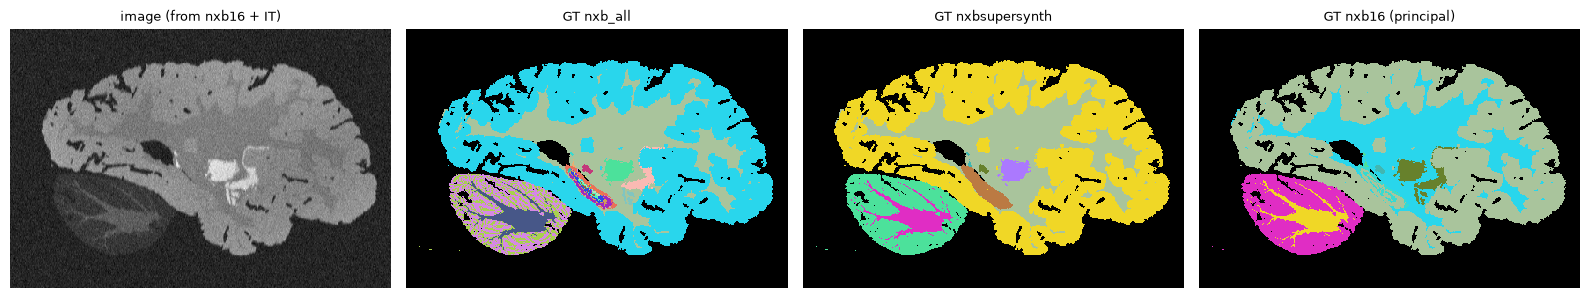

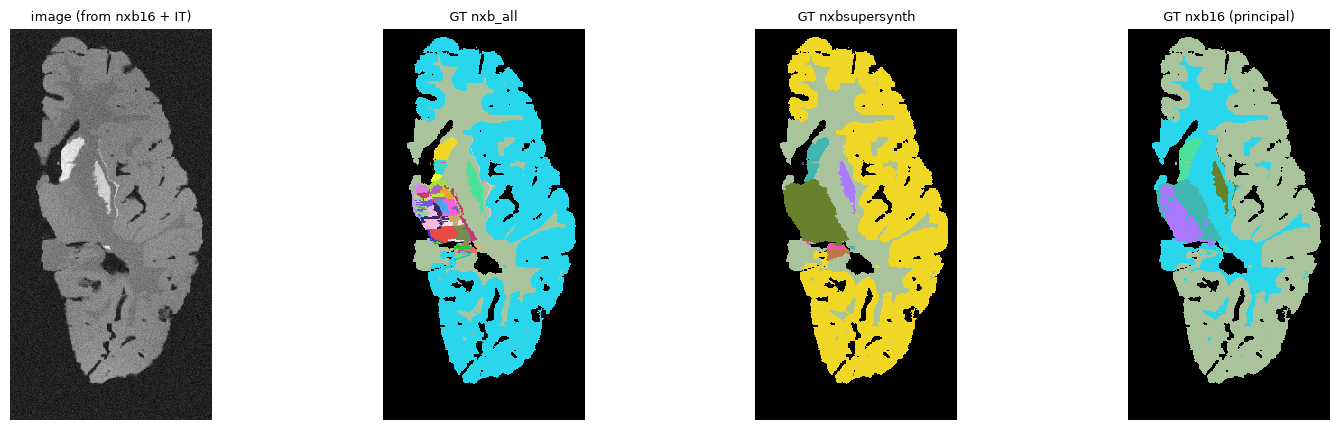

In [8]:
vols = [s.image] + [s.segs[n] for n in ['nxb_all', 'nxbsupersynth', 'nxb16']]
titles = ['image (from nxb16 + IT)', 'GT nxb_all', 'GT nxbsupersynth', 'GT nxb16 (principal)']
show(vols, titles, axis=0, size=4)
show(vols, titles, axis=2, size=4)

Same shapes in the four panels: there is one augmentation (morphology + deformation) and every GT
is derived from it. Colours are arbitrary per panel (random colour per index).

## 4. Inside `render`

```
crop ► morphology ► spatial                       fine labels, HR grid (unchanged from generator_tree)
for every level (principal last):
    merge_<level>            lut[fine HR labels]          HR grid, level indices
    partial_volume_<level>   downsample to the output grid → GT of the level
                             principal: top-k fractions kept (for the synthesis)
                             others: top-1 only (the hard label is the same for any k)
synthesis ► bias ► motion ► resolution ► noise ► normalization   (principal level only)
```

The `Recorder` shows every intermediate step (`merge_<level>`, `pv_seg_<level>`, and `pv_seg` =
the principal one). Here a zoom on the cortex, HR grid then output grid:

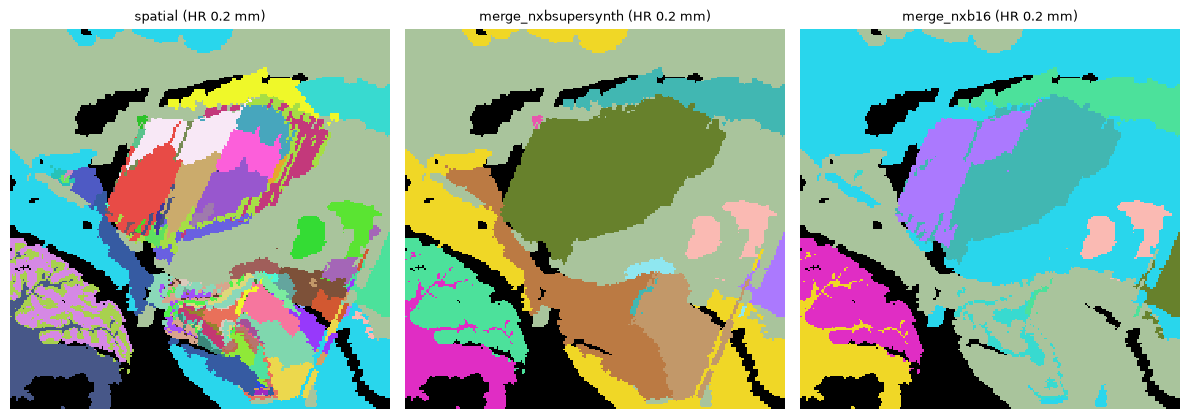

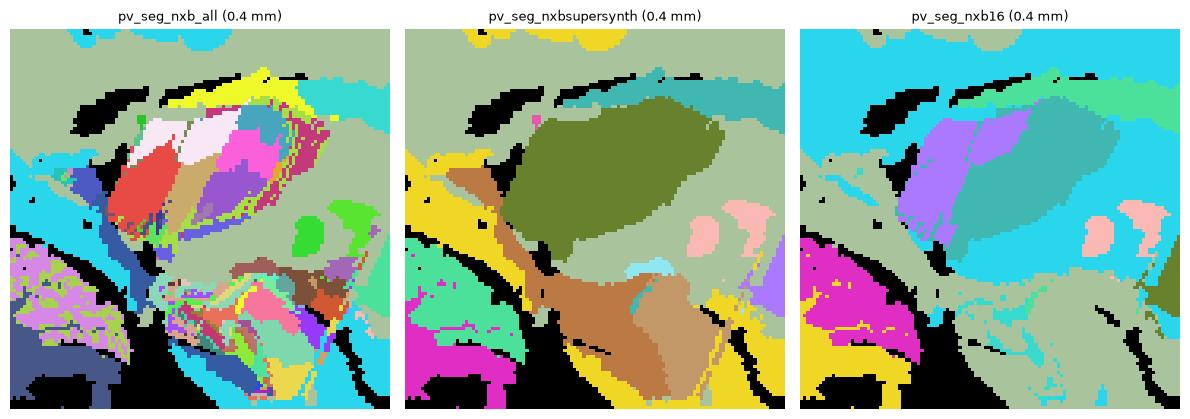

In [9]:
steps = ['spatial', 'merge_nxbsupersynth', 'merge_nxb16', 'pv_seg_nxb_all', 'pv_seg_nxbsupersynth', 'pv_seg_nxb16']
rec = Recorder(steps=steps)
s = gen(2, recorder=rec)
# zoom on the deep grey matter: a box around the thalamus/hippocampus labels of nxbsupersynth
ss = gen.levels['nxbsupersynth'].labels
deep = torch.isin(s.segs['nxbsupersynth'].cpu(), torch.tensor([ss.index[53], ss.index[49]]))  # hippocampus, thalamus
x = int(deep.sum((1, 2)).argmax())
ys, zs = torch.nonzero(deep[x], as_tuple=True)
cy, cz = int(ys.float().mean()), int(zs.float().mean())
lr = (slice(cy - 60, cy + 60), slice(cz - 60, cz + 60))                          # output voxels
hr = (slice(2 * (cy - 60), 2 * (cy + 60)), slice(2 * (cz - 60), 2 * (cz + 60)))  # same box, HR voxels
show([rec.steps[n][2 * x][hr].numpy() for n in steps[:3]], [f'{n} (HR 0.2 mm)' for n in steps[:3]],
     labels=[True] * 3, size=4)
show([rec.steps[n][x][lr].numpy() for n in steps[3:]], [f'{n} (0.4 mm)' for n in steps[3:]],
     labels=[True] * 3, size=4)

## 5. How each level's GT is decided: merge first, consistent ties

Each output voxel (0.4 mm) covers 2×2×2 = 8 HR voxels. Two rules give the hard label of a level:

1. **the class of the level with the largest fraction of the voxel wins**: the HR labels are
   merged *first*, then the partial volume is taken;
2. **ties go to the class of the fine hard label** (the `nxb_all` GT of that voxel).

**Rule 1**: a fine structure split into parcels. Take a voxel at a boundary:

| HR voxels | fine label | class (nxb16) |
|---|---|---|
| 2 | parcel A | GM |
| 2 | parcel B | GM |
| 1 | parcel C | GM |
| 3 | white matter | WM |

* merge *after* (PV of the fine labels, then relabel): the fine winner is WM (3/8, every parcel
  has less) → **WM**;
* merge *before* (relabel the HR voxels, then PV): GM covers 5/8 of the voxel → **GM**.

Merging first asks the right question for each level (*which class covers most of the voxel?*),
which is also what the image sees: the synthesis mixes the classes with their true fractions.

**Rule 2**: ties are very common at factor 2 (a flat boundary through a voxel gives 4/8 vs 4/8).
Partial volume breaks ties by the smallest index, and index order differs between levels (in the
fine space the cortex, raw 3, comes before the white matter, raw 7; in nxb16 white matter = 1
comes before grey matter = 2). Without rule 2 about **1 % of the voxels**, nearly all on the
cortex / white-matter boundary, would disagree between levels for no anatomical reason. With it, a
level differs from the relabelled fine GT **only** where rule 1 applies.

In [10]:
from nxgen.online import partial_volume as PV
lut = torch.tensor([0, 1, 1, 1, 2], dtype=torch.int16)          # fine 1, 2, 3 (parcels) -> GM (1), 4 -> WM (2)
def both(fine):
    fine = torch.tensor(fine, dtype=torch.int16).view(2, 2, 2)
    fine_gt = PV.apply(fine, 'downsample', 2, 1)['seg']
    merged = PV.apply(lut[fine.long()], 'downsample', 2, 1, prefer=lut[fine_gt.long()])['seg']
    return int(lut[fine_gt.long()]), int(merged)
print('rule 1, 2+2+1 parcels vs 3 WM : merge after -> %d, merge first -> %d (GM = 1)' % both([1, 1, 2, 2, 3, 4, 4, 4]))
print('rule 2, 4 WM vs 2+2 parcels   : merge after -> %d, merge first -> %d (tie GM/WM 4:4, fine winner WM)' % both([4, 4, 4, 4, 1, 1, 2, 2]))

rule 1, 2+2+1 parcels vs 3 WM : merge after -> 2, merge first -> 1 (GM = 1)
rule 2, 4 WM vs 2+2 parcels   : merge after -> 2, merge first -> 2 (tie GM/WM 4:4, fine winner WM)


On the real image, where does a level differ from its relabelled fine GT?

nxb16             864 voxels (0.011 % of the foreground)
                   342  relabelled hippocampal_white_matter   -> merged first gray_matter
                    79  relabelled white_thalamus             -> merged first gray_thalamus
                    73  relabelled white_matter               -> merged first gray_matter
nxbsupersynth     577 voxels (0.008 % of the foreground)
                   107  relabelled cerebral_cortex            -> merged first cerebral_white_matter
                    82  relabelled cerebral_white_matter      -> merged first hippocampus
                    76  relabelled cerebral_white_matter      -> merged first thalamus


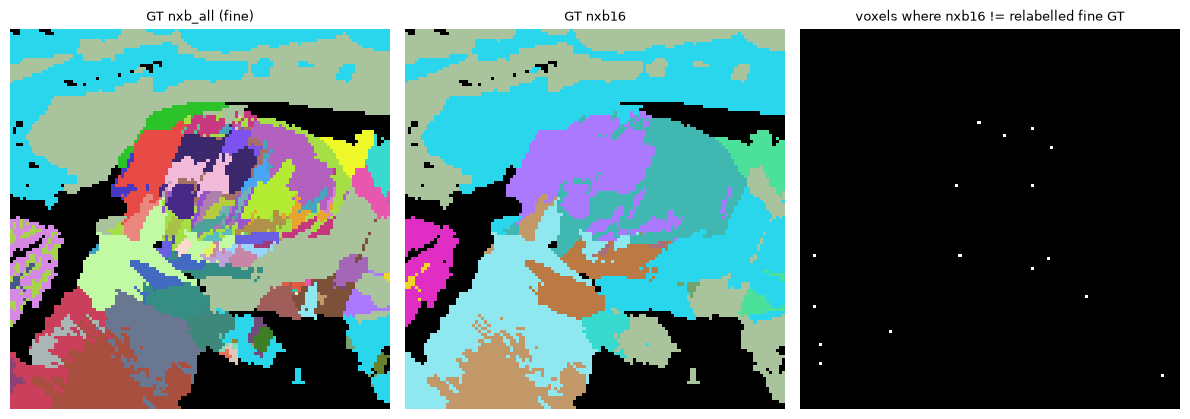

In [11]:
from collections import Counter
fg = s.segs['nxb_all'] > 0
for name in ['nxb16', 'nxbsupersynth']:
    lv = gen.levels[name]
    relabel = lv.lut[s.segs['nxb_all'].long()]                          # merge AFTER the PV
    diff = (relabel != s.segs[name]) & fg
    top = Counter(zip(relabel[diff].tolist(), s.segs[name][diff].tolist())).most_common(3)
    print(f'{name:14s} {int(diff.sum()):6d} voxels ({100 * diff.sum().item() / fg.sum().item():.3f} % of the foreground)')
    for (i, j), n in top:
        print(f'{"":17s}{n:5d}  relabelled {lv.labels.names[i]:26s} -> merged first {lv.labels.names[j]}')
diff16 = (gen.levels['nxb16'].lut[s.segs['nxb_all'].long()] != s.segs['nxb16']).cpu()
x = int(diff16.sum((1, 2)).argmax())
show([s.segs['nxb_all'][x][lr], s.segs['nxb16'][x][lr], diff16[x][lr].to(torch.uint8)],
     ['GT nxb_all (fine)', 'GT nxb16', 'voxels where nxb16 != relabelled fine GT'],
     labels=[True, True, False], size=4)

About 0.01 % of the voxels, on the boundaries of finely parcellated structures (hippocampal
subfields, thalamic nuclei): exactly the voxels where a relabelled fine GT would under-represent
the parcellated class.

## 6. The image comes from the principal level and IT

`plan['tree']` is drawn from **IT** with the **principal label space**: one Gaussian per nxb16
label, not per fine label. MT plays no role in the intensities (its `r_max` / visibility is not
used); it only shapes the labels.

In [12]:
p = s.plan['tree']
print('Gaussians in the plan:', len(p['mu']), '= labels of nxb16:', len(gen.levels['nxb16'].labels))
print('principal colours C (one per IT colour):', dict(zip(gen.itree.colors, np.round(p['colors_mu'], 1))))
print()
img = s.image.cpu()
pv_seg = s.segs['nxb16'].cpu()
print(f'{"nxb16 class":42s} {"mu":>7s} {"sigma":>6s} {"image mean":>10s} {"std":>6s}')
for i, name in enumerate(gen.levels['nxb16'].labels.names):
    m = pv_seg == i
    if m.sum() == 0:
        continue
    print(f'{name[:42]:42s} {p["mu"][i]:7.1f} {p["sigma"][i]:6.2f} {img[m].mean():10.3f} {img[m].std():6.3f}')

Gaussians in the plan: 17 = labels of nxb16: 17
principal colours C (one per IT colour): {'WM': np.float64(99.5), 'GM': np.float64(120.1), 'WMC': np.float64(58.3), 'GMC': np.float64(19.7), 'CA': np.float64(226.9), 'PU': np.float64(206.3), 'PA': np.float64(0.3)}



nxb16 class                                     mu  sigma image mean    std
background                                     0.0   0.00      0.164  0.035
white_matter                                  99.5   0.76      0.458  0.037
gray_matter                                  120.1   2.26      0.504  0.045
cerebellum_white_matter                       58.3   2.55      0.334  0.044
cerebellum_gray_matter                        19.7   1.39      0.229  0.033
caudate_and_accumbens                        226.9   1.90      0.807  0.067
putamen                                      206.3   0.44      0.727  0.053
white_thalamus                               107.2   1.32      0.494  0.035
gray_thalamus                                112.3   1.70      0.511  0.034
pallidum                                       0.3   1.45      0.203  0.058
substantia_nigra_and_stn_and_red_nucleus      87.8   0.76      0.450  0.033
gray_brainstem_nuclei                        100.7   0.85      0.493  0.041
white_brains

The image mean of a class follows its `mu` (up to bias field and normalisation; the std is larger
than `sigma` because of bias, partial volume and noise).

## 7. Changing the principal level

`principal` only changes which level paints the image. Every module draws from its own random
stream (notebook 01), so with the same seed the **acquisition, morphology, deformation, bias,
motion and noise are identical**; only `plan['tree']` changes (other tree, other label space).
The ground truths are identical too.

same sections: ['version', 'seed', 'template', 'template_path', 'roi', 'acquisition', 'morphology', 'spatial', 'bias', 'motion', 'noise']
different    : ['config_hash', 'tree']
same GTs     : True


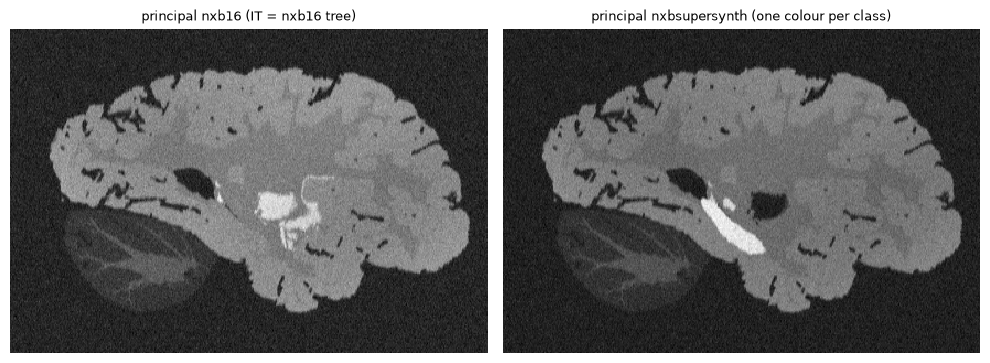

In [13]:
cfg_ss = load_config(DT_CONFIG, merging={'principal': 'nxbsupersynth'})
gen_ss = Generator([DT_TEMPLATE], cfg_ss, label_space=gen.labels, device=DEVICE)
a, b = gen.sample_plan(2), gen_ss.sample_plan(2)
print('same sections:', [k for k in a if a[k] == b[k]])
print('different    :', [k for k in a if a[k] != b[k]])
sb = gen_ss.render(b)
print('same GTs     :', all(torch.equal(s.segs[n], sb.segs[n]) for n in s.segs))
show([s.image, sb.image], ['principal nxb16 (IT = nxb16 tree)', 'principal nxbsupersynth (one colour per class)'],
     axis=0, size=5)
del gen_ss, sb

## 8. Saving, checks, cost

### Saving datasets

`python -m nxgen.cli.generate --config configs/nxbsimplified_levels.json ...` writes, per image:

```
imagesTr/<case>_0000.nii.gz        image
labelsTr/<case>.nii.gz             GT of the principal level (nnU-Net reads this one)
levels/<level>/<case>.nii.gz       GT of every level (label indices of that level)
plans/<case>.json                  the plan
label_space.json                   fine label space (MT)
label_spaces/<level>.json          label space of every level (frozen: a later run with a
                                   different mapping or tree raises an error)
configs/<hash>/tree_<level>.json   copy of every level tree
```

The test driver `generator/test_generators/test_double_tree_generator/generate.py` writes the GTs
with raw label values instead (`labels/<level>/synth_<i>.nii.gz`).

### Checks (all at start-up, never silent)

* a fine label missing from a script's mapping → error naming the labels;
* a merged value missing from the level tree → error;
* the background must map to itself;
* `principal` must be one of the levels.

In [14]:
from nxgen.core.merging import build_level
try:
    bad = dict(spec16, options={})
    # pretend the mapping lost label 3 (unparcellated cortex)
    mod = load_script(spec16['script'])
    orig = mod.label_mapping
    mod.label_mapping = lambda **kw: {k: v for k, v in orig(**kw).items() if k != 3}
    build_level('nxb16', bad, gen.tree, gen.labels)
except ValueError as e:
    print('error:', e)
finally:
    mod.label_mapping = orig
try:
    load_config(DT_CONFIG, merging={'principal': 'nxb32'})
except ValueError as e:
    print('error:', e)

error: Level 'nxb16': labels [3] are not in the mapping of /home/agustin/phd/synthseg_nextbrain/project/dev2/simplified_trees_and_labels/nxbsimplified_to_nxb16.py
error: merging.principal 'nxb32' is not a level (['nxb16', 'nxb_all', 'nxbsupersynth'])


### Cost per image (full volume, `profile=True`)

In [ ]:
gen(0)                                              # warm-up
acc = {}
for sd in range(1, 4):
    r = Recorder(profile=True)
    gen(sd, recorder=r)
    for n, tm in r.timings.items():
        acc.setdefault(n, []).append(tm)
total = 0
for n, v in acc.items():
    t = np.median([x['time_s'] for x in v]); total += t
    peak = max(x['peak_gb'] or 0 for x in v)
    print(f'{n:28s} {t:7.3f} s   peak {peak:5.2f} GB')
print(f'{"total":28s} {total:7.3f} s')

crop                           0.000 s   peak  1.18 GB
morphology                     0.163 s   peak  7.11 GB
spatial                        0.045 s   peak  3.28 GB
partial_volume_fine            0.071 s   peak  2.34 GB
merge_nxbsupersynth            0.002 s   peak  4.26 GB
partial_volume_nxbsupersynth   0.077 s   peak  3.21 GB
merge_nxb16                    0.002 s   peak  4.31 GB
partial_volume_nxb16           0.174 s   peak  4.46 GB
synthesis                      0.023 s   peak  4.80 GB
bias                           0.001 s   peak  1.69 GB
motion                         0.000 s   peak  1.46 GB
resolution                     0.004 s   peak  1.72 GB
normalization                  0.000 s   peak  1.78 GB
total                          0.562 s


: 

The merge is a gather (milliseconds). Each extra level costs one top-1 partial volume, which is
cheaper than the principal's top-k one.

## Summary

| | single tree (`generator_tree`) | double tree (this package) |
|---|---|---|
| label shapes (morphology, deformation) | tree | **MT** (`labels.tree`) |
| ground truths | 1 | **1 per level** (`merging.levels`), merged online after the augmentation, then partial volume |
| image intensities | same tree | **IT** = tree of `merging.principal` |
| `Sample` | `image`, `seg` | `image`, `seg` (principal), **`segs`** |

Without a `merging` section the generator behaves exactly as the single-tree one (one identity
level `all`, IT = MT): every older config and notebook still works.